<a href="https://colab.research.google.com/github/Kiiyoko123/well-free-acoustic-impedance-with-B-PINN/blob/main/E1_BPINN_1D_5seeds_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E1 — 1D well-free impedance inversion: MAP vs VI vs HMC vs deep ensemble

**What this notebook does.** It makes one *synthetic* 1D impedance trace (the "answer key" is known), generates its seismic trace with one operator, and then tries to recover the impedance from the seismic **only** with a different operator (so there is no inverse crime). Four estimators are compared:

| Method | What it gives |
|---|---|
| MAP | one best guess (non-Bayesian PINN baseline) |
| VI | a guess + uncertainty, fast and approximate (main method) |
| HMC | a guess + uncertainty, slow and accurate (1D reference) |
| Deep ensemble | a guess + spread from 20 independently trained networks |

**How to run.** `Runtime > Run all`. It runs the five seeds in `SEEDS` (default 0 to 4) and prints the table used in the report (mean and std over seeds), plus the figures for the first seed. One seed takes roughly 2 to 5 minutes on the free Colab CPU, so the full run is about 10 to 25 minutes (a GPU is not needed). For a quick look set `QUICK = True` (rough results) or `SEEDS = [0]`.

**Units.** Impedance Zp is in MRayl (10^6 kg m^-2 s^-1). Time is in ms.

In [ ]:
import json, time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from types import SimpleNamespace

torch.set_default_dtype(torch.float64)   # float64 keeps HMC numerically stable
print("torch", torch.__version__)

torch 2.11.0+cpu


## 1. Input: configuration

Everything you may want to change is here.

In [ ]:
QUICK = False          # True = fast smoke test (results are rough)
SEEDS = [0, 1, 2, 3, 4]  # seeds of the report table; each seed = new random trace + new initialisations

cfg = SimpleNamespace(
    seed=0,              # set automatically inside the seed loop (do not edit here)
    n=80,                # samples per trace (coarse grid)
    dt=0.004,            # sampling interval, s (4 ms)
    fm=25.0,             # Ricker peak frequency, Hz
    hidden=16,           # hidden units of the small network
    sigma_p=0.1,         # std of the Gaussian prior on every network weight
    sigma_d_frac=0.10,   # data tolerance sigma_d as a fraction of std(seismic)
    n_ens=20,            # deep-ensemble members
    map_steps=4000,      # Adam steps for MAP and for each ensemble member
    vi_steps=8000,       # Adam steps for VI
    vi_mc=8,             # Monte Carlo weight draws per VI step
    hmc_warmup=1000,     # HMC warm-up iterations (step size is adapted here)
    hmc_samples=2000,    # HMC iterations kept after warm-up
    hmc_thin=5,          # keep every 5th HMC sample
    n_post=300,          # posterior draws taken from the VI posterior
)
if QUICK:
    cfg.map_steps, cfg.vi_steps, cfg.hmc_warmup, cfg.hmc_samples, cfg.n_ens = 800, 1500, 200, 300, 5
rng = np.random.default_rng(cfg.seed)
torch.manual_seed(cfg.seed)

## 2. Physics: forward model (data generation vs inversion operator)

In [ ]:
def ricker(t, fm):
    a = (np.pi * fm * t) ** 2
    return (1.0 - 2.0 * a) * np.exp(-a)


def make_truth_fine(rng, nf):
    """Blocky impedance (MRayl) on the fine grid; layer boundaries at fine resolution."""
    z = np.empty(nf)
    i, prev = 0, None
    while i < nf:
        th = int(rng.integers(6, 28))
        val = rng.uniform(5.5, 13.5)
        while prev is not None and abs(val - prev) < 1.2:
            val = rng.uniform(5.5, 13.5)
        z[i:i + th] = val
        prev = val
        i += th
    return z


def synth_data_fine(z_fine, dt, fm, half=0.064):
    """Data generation operator (FINE grid): r = 0.5 d(ln Z)/dt, conv. with Ricker, decimate."""  # noqa
    dtf = dt / 2.0
    m = np.log(z_fine)
    r = np.zeros_like(m)
    r[1:-1] = 0.25 * (m[2:] - m[:-2])          # centred difference (0.5 d m/dt)
    kf = int(round(half / dtf))
    w = ricker(np.arange(-kf, kf + 1) * dtf, fm)
    d = np.convolve(r, w, mode="same")
    return d[::2]


def build_G(n, dt, fm, half=0.064):
    """Inversion operator (COARSE grid): G = C D as an n x n matrix."""
    D = np.zeros((n, n))
    for i in range(1, n - 1):                   # centred difference (0.5 d m/dt)
        D[i, i - 1] = -0.25
        D[i, i + 1] = 0.25
    k = int(round(half / dt))
    w = ricker(np.arange(-k, k + 1) * dt, fm)
    C = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if abs(i - j) <= k:
                C[i, j] = w[(i - j) + k]
    return torch.tensor(C @ D)


## 3. Network, prior, likelihood

In [ ]:
class Shapes:
    """Flat parameter vector <-> (W1, b1, W2, b2) for  delta_m = W2 tanh(W1 x + b1) + b2."""

    def __init__(self, n, h):
        self.n, self.h = n, h
        self.P = h * n + h + n * h + n

    def unpack(self, th):
        n, h = self.n, self.h
        i = 0
        W1 = th[i:i + h * n].view(h, n); i += h * n
        b1 = th[i:i + h]; i += h
        W2 = th[i:i + n * h].view(n, h); i += n * h
        b2 = th[i:i + n]
        return W1, b1, W2, b2


class Problem:
    def __init__(self, G, d_obs, m_lf, x_in, sigma_d, sigma_p, shapes):
        self.G, self.d, self.m_lf, self.x = G, d_obs, m_lf, x_in
        self.sd, self.sp, self.S = sigma_d, sigma_p, shapes

    def delta_m(self, th):
        W1, b1, W2, b2 = self.S.unpack(th)
        return W2 @ torch.tanh(W1 @ self.x + b1) + b2

    def misfit(self, th):  # -ln P(D|theta) up to a constant
        m = self.m_lf + self.delta_m(th)
        r = self.d - self.G @ m
        return 0.5 * (r ** 2).sum() / self.sd ** 2

    def U(self, th):  # HMC potential: -ln likelihood - ln prior
        return self.misfit(th) + 0.5 * (th ** 2).sum() / self.sp ** 2

    def zp(self, th):  # MRayl
        return torch.exp(self.m_lf + self.delta_m(th))


## 4. Fitting routines (MAP, VI, HMC) and metrics

In [ ]:
def fit_map(pb, theta0, steps, lr=1e-2, prior=True, wd=0.0):
    th = theta0.clone().requires_grad_(True)
    opt = torch.optim.Adam([th], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        opt.zero_grad()
        loss = pb.U(th) if prior else pb.misfit(th) + wd * (th ** 2).sum()
        loss.backward()
        opt.step()
        sched.step()
    return th.detach()


def fit_vi(pb, steps, mc, lr=3e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    P, sp = pb.S.P, pb.sp
    mu = (torch.randn(P, generator=g) * 0.1).requires_grad_(True)
    rho = torch.full((P,), -4.0, requires_grad=True)
    opt = torch.optim.Adam([mu, rho], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist = []
    for it in range(steps):
        opt.zero_grad()
        s = F.softplus(rho)
        data = 0.0
        for _ in range(mc):
            th = mu + s * torch.randn(P, generator=g)
            data = data + pb.misfit(th)
        data = data / mc
        kl = (torch.log(sp / s) + (s ** 2 + mu ** 2) / (2 * sp ** 2) - 0.5).sum()
        loss = data + kl
        loss.backward()
        opt.step()
        sched.step()
        if it % max(1, steps // 20) == 0:
            hist.append((it, float(data.detach()), float(kl.detach())))
    return mu.detach(), F.softplus(rho).detach(), hist


def run_hmc(pb, loc, scale, n_warm, n_samp, thin, seed=0, eps0=1e-2, target=0.8):
    """HMC in whitened coordinates z, theta = loc + scale * z.
    loc/scale come from the VI posterior and only act as a preconditioner:
    the sampled target is still P(theta | D) (the Jacobian is constant)."""
    rng = np.random.default_rng(seed)
    g = torch.Generator().manual_seed(seed)

    def ug(z):
        z = z.detach().requires_grad_(True)
        u = pb.U(loc + scale * z)
        (gr,) = torch.autograd.grad(u, z)
        return float(u.detach()), gr

    z, eps = torch.zeros_like(loc), eps0
    u0, g0 = ug(z)
    samples, utrace, acc_flags = [], [], []
    for i in range(n_warm + n_samp):
        p = torch.randn(pb.S.P, generator=g)
        h0 = u0 + 0.5 * float(p @ p)
        L = int(rng.integers(10, 31))
        t, pp, gg = z.clone(), p - 0.5 * eps * g0, g0
        for l in range(L):
            t = t + eps * pp
            u1, gg = ug(t)
            if l < L - 1:
                pp = pp - eps * gg
        pp = pp - 0.5 * eps * gg
        h1 = u1 + 0.5 * float(pp @ pp)
        a = min(1.0, float(np.exp(h0 - h1))) if np.isfinite(h1) else 0.0
        if rng.random() < a:
            z, u0, g0 = t, u1, gg
            acc_flags.append(1)
        else:
            acc_flags.append(0)
        if i < n_warm:
            eps *= float(np.exp(0.1 * (a - target)))
        else:
            utrace.append(u0)
            if (i - n_warm) % thin == 0:
                samples.append((loc + scale * z).clone())
    acc = float(np.mean(acc_flags[n_warm:]))
    return torch.stack(samples), np.array(utrace), acc, eps


def ess_1d(x):
    """Effective sample size of a scalar chain (Geyer initial positive sequence)."""
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    if x.std() == 0:
        return float(n)
    f = np.fft.rfft(x, 2 * n)
    ac = np.fft.irfft(f * np.conj(f))[:n]
    ac = ac / ac[0]
    s = 0.0
    for k in range(0, n - 1, 2):
        pair = ac[k] + ac[k + 1]
        if pair < 0:
            break
        s += pair
    tau = max(1.0, -1.0 + 2.0 * s)
    return float(n / tau)


In [ ]:
LEVELS = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95])


def summarize(z_samp, z_true):
    """z_samp: (S, n) posterior/ensemble Zp samples (MRayl)."""
    mean = z_samp.mean(0)
    lo, hi = np.quantile(z_samp, [0.05, 0.95], axis=0)
    cov = {}
    for lv in LEVELS:
        a = (1 - lv) / 2
        l, h = np.quantile(z_samp, [a, 1 - a], axis=0)
        cov[float(lv)] = float(np.mean((z_true >= l) & (z_true <= h)))
    return dict(
        corr=float(np.corrcoef(mean, z_true)[0, 1]),
        mae=float(np.mean(np.abs(mean - z_true))),
        picp90=cov[0.9],
        width90=float(np.mean(hi - lo)),
        coverage=cov,
    ), mean, lo, hi


## 5. One full experiment for one seed

The function below does everything for a given seed:

* **True impedance** `z_true`: blocky trace, 5.5 to 13.5 MRayl. Used **only** for scoring, never for training.
* **Seismic** `d`: made on a finer grid, then decimated (data-generation operator).
* **Background** `m_lf`: straight-line trend of ln Zp (the compaction-like low-frequency model).
* **Inversion operator** `G`: built on the coarse grid (a different discretisation, so no inverse crime).
* **MAP** (non-Bayesian PINN baseline), **VI** (main method), **HMC** (reference posterior, 1D only; started at the VI mean, VI std used only to rescale coordinates, step size tuned to about 80 percent acceptance during warm-up, 10 to 30 leapfrog steps), and a **deep ensemble** of `n_ens` networks (no prior, weight decay 1e-4).

In [ ]:
def run_seed(seed, verbose=True):
    """Build the data for this seed, then fit MAP, VI, HMC and the deep ensemble. Returns a dict."""
    cfg.seed = seed
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    n = cfg.n
    z_fine = make_truth_fine(rng, 2 * n)
    z_true = z_fine[::2].copy()
    d = synth_data_fine(z_fine, cfg.dt, cfg.fm)
    G = build_G(n, cfg.dt, cfg.fm)
    m_true = np.log(z_true)
    tt = np.arange(n)
    m_lf = np.polyval(np.polyfit(tt, m_true, 1), tt)      # linear trend in ln Zp (background)
    d_t = torch.tensor(d)
    sd_d = float(d_t.std())
    sigma_d = cfg.sigma_d_frac * sd_d
    mismatch = float(torch.linalg.norm(d_t - G @ torch.tensor(m_true)) / torch.linalg.norm(d_t))
    shapes = Shapes(n, cfg.hidden)
    pb = Problem(G, d_t, torch.tensor(m_lf), d_t / sd_d, sigma_d, cfg.sigma_p, shapes)
    if verbose:
        print(f"[seed {seed}] n={n}, params={shapes.P}, sigma_d={sigma_d:.4f}, operator mismatch={mismatch:.3f}")
    out = dict(z_true=z_true, d=d, m_lf=m_lf, sigma_d=sigma_d, mismatch=mismatch, n_params=shapes.P)

    t0 = time.time()                                       # --- MAP
    th_map = fit_map(pb, torch.randn(shapes.P) * cfg.sigma_p, cfg.map_steps, prior=True)
    z_map = pb.zp(th_map).numpy()
    res = {"MAP": dict(corr=float(np.corrcoef(z_map, z_true)[0, 1]), mae=float(np.mean(np.abs(z_map - z_true))))}
    if verbose: print(f"  MAP  corr={res['MAP']['corr']:.3f}  MAE={res['MAP']['mae']:.3f}   ({time.time()-t0:.0f}s)")

    t0 = time.time()                                       # --- VI
    mu, s, hist = fit_vi(pb, cfg.vi_steps, cfg.vi_mc, seed=seed)
    gdraw = torch.Generator().manual_seed(seed + 1)
    z_vi = np.stack([pb.zp(mu + s * torch.randn(shapes.P, generator=gdraw)).numpy() for _ in range(cfg.n_post)])
    res["VI"], mean_vi, lo_vi, hi_vi = summarize(z_vi, z_true)
    if verbose: print(f"  VI   corr={res['VI']['corr']:.3f}  MAE={res['VI']['mae']:.3f}  PICP90={res['VI']['picp90']:.2f}  width90={res['VI']['width90']:.2f}   ({time.time()-t0:.0f}s)")

    t0 = time.time()                                       # --- HMC (reference posterior)
    samples, utrace, acc, eps = run_hmc(pb, mu, s, cfg.hmc_warmup, cfg.hmc_samples, cfg.hmc_thin, seed=seed)
    z_hmc = np.stack([pb.zp(t).numpy() for t in samples])
    res["HMC"], mean_hmc, lo_hmc, hi_hmc = summarize(z_hmc, z_true)
    res["HMC"].update(accept_rate=acc, step_size=eps, ess_potential=ess_1d(utrace))
    if verbose: print(f"  HMC  corr={res['HMC']['corr']:.3f}  MAE={res['HMC']['mae']:.3f}  PICP90={res['HMC']['picp90']:.2f}  width90={res['HMC']['width90']:.2f}  accept={acc:.2f}  ESS={res['HMC']['ess_potential']:.0f}   ({time.time()-t0:.0f}s)")

    t0 = time.time()                                       # --- deep ensemble
    z_ens = []
    for e in range(cfg.n_ens):
        g = torch.Generator().manual_seed(1000 + e)
        th_e = torch.randn(shapes.P, generator=g) * cfg.sigma_p
        z_ens.append(pb.zp(fit_map(pb, th_e, cfg.map_steps, prior=False, wd=1e-4)).numpy())
    z_ens = np.stack(z_ens)
    res["Ensemble"], mean_ens, lo_ens, hi_ens = summarize(z_ens, z_true)
    if verbose: print(f"  ENS  corr={res['Ensemble']['corr']:.3f}  MAE={res['Ensemble']['mae']:.3f}  PICP90={res['Ensemble']['picp90']:.2f}  width90={res['Ensemble']['width90']:.2f}   ({time.time()-t0:.0f}s)")

    out.update(res=res, z_map=z_map, z_vi=z_vi, z_hmc=z_hmc, z_ens=z_ens,
               bands={"VI": (mean_vi, lo_vi, hi_vi), "HMC": (mean_hmc, lo_hmc, hi_hmc), "Ensemble": (mean_ens, lo_ens, hi_ens)})
    return out


## 6. Run all seeds

This is the slow cell (HMC and the ensemble dominate). Results are printed per seed.

In [ ]:
ALL = {}
for sd_ in SEEDS:
    ALL[sd_] = run_seed(sd_)
print('done:', list(ALL))

[seed 0] n=80, params=2656, sigma_d=0.0148, operator mismatch=0.159
  MAP  corr=0.854  MAE=1.118   (13s)
  VI   corr=0.793  MAE=1.280  PICP90=0.62  width90=2.52   (39s)
  HMC  corr=0.846  MAE=1.167  PICP90=1.00  width90=6.03  accept=0.81  ESS=154   (36s)
  ENS  corr=0.958  MAE=0.630  PICP90=0.99  width90=5.28   (63s)
[seed 1] n=80, params=2656, sigma_d=0.0107, operator mismatch=0.202
  MAP  corr=0.965  MAE=0.521   (4s)
  VI   corr=0.890  MAE=0.907  PICP90=0.59  width90=2.00   (36s)
  HMC  corr=0.940  MAE=0.695  PICP90=0.99  width90=6.05  accept=0.84  ESS=170   (40s)
  ENS  corr=0.976  MAE=0.418  PICP90=1.00  width90=4.80   (64s)
[seed 2] n=80, params=2656, sigma_d=0.0134, operator mismatch=0.156
  MAP  corr=0.943  MAE=0.461   (3s)
  VI   corr=0.913  MAE=0.568  PICP90=0.96  width90=2.74   (37s)
  HMC  corr=0.922  MAE=0.579  PICP90=1.00  width90=6.00  accept=0.84  ESS=140   (37s)
  ENS  corr=0.941  MAE=0.473  PICP90=0.97  width90=5.22   (63s)
[seed 3] n=80, params=2656, sigma_d=0.0137, o

## 7. Output: table (mean and std over seeds)

This is Table 2 of the report.

In [ ]:
METHODS = ["MAP", "VI", "HMC", "Ensemble"]
KEYS = ["corr", "mae", "picp90", "width90"]
print(f"E1, {len(ALL)} seeds {list(ALL)}  (mean +- std; MAE and width90 in MRayl)")
print(f"{'method':10s} {'corr':>13s} {'MAE':>13s} {'PICP90':>13s} {'width90':>13s}")
summary = {}
for m_ in METHODS:
    row, summary[m_] = [], {}
    for k_ in KEYS:
        v = [ALL[s_]["res"][m_][k_] for s_ in ALL if k_ in ALL[s_]["res"][m_]]
        if v:
            summary[m_][k_] = (float(np.mean(v)), float(np.std(v)))
            row.append(f"{np.mean(v):5.2f} +- {np.std(v):4.2f}")
        else:
            row.append("-")
    print(f"{m_:10s} " + " ".join(f"{x:>13s}" for x in row))
print("\nper seed:")
for s_ in ALL:
    print(s_, {m_: tuple(round(ALL[s_]["res"][m_].get(k_, float('nan')), 2) for k_ in KEYS) for m_ in METHODS})
print("\nHMC accept rate / ESS per seed:", [(round(ALL[s_]["res"]["HMC"]["accept_rate"], 2), round(ALL[s_]["res"]["HMC"]["ess_potential"])) for s_ in ALL])

E1, 5 seeds [0, 1, 2, 3, 4]  (mean +- std; MAE and width90 in MRayl)
method              corr           MAE        PICP90       width90
MAP         0.92 +- 0.04  0.69 +- 0.23             -             -
VI          0.86 +- 0.04  0.91 +- 0.23  0.70 +- 0.17  2.31 +- 0.31
HMC         0.90 +- 0.03  0.80 +- 0.20  1.00 +- 0.00  5.97 +- 0.16
Ensemble    0.96 +- 0.01  0.48 +- 0.08  0.99 +- 0.01  5.04 +- 0.23

per seed:
0 {'MAP': (0.85, 1.12, nan, nan), 'VI': (0.79, 1.28, 0.62, 2.52), 'HMC': (0.85, 1.17, 1.0, 6.03), 'Ensemble': (0.96, 0.63, 0.99, 5.28)}
1 {'MAP': (0.96, 0.52, nan, nan), 'VI': (0.89, 0.91, 0.59, 2.0), 'HMC': (0.94, 0.69, 0.99, 6.05), 'Ensemble': (0.98, 0.42, 1.0, 4.8)}
2 {'MAP': (0.94, 0.46, nan, nan), 'VI': (0.91, 0.57, 0.96, 2.74), 'HMC': (0.92, 0.58, 1.0, 6.0), 'Ensemble': (0.94, 0.47, 0.97, 5.22)}
3 {'MAP': (0.91, 0.68, nan, nan), 'VI': (0.88, 0.79, 0.84, 2.34), 'HMC': (0.9, 0.74, 1.0, 5.66), 'Ensemble': (0.95, 0.47, 1.0, 4.72)}
4 {'MAP': (0.92, 0.66, nan, nan), 'VI': (0.83,

## 8. Figures for the first seed

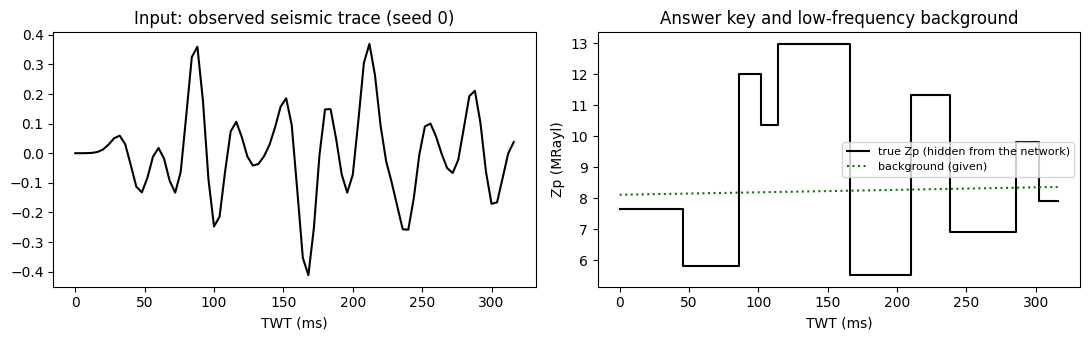

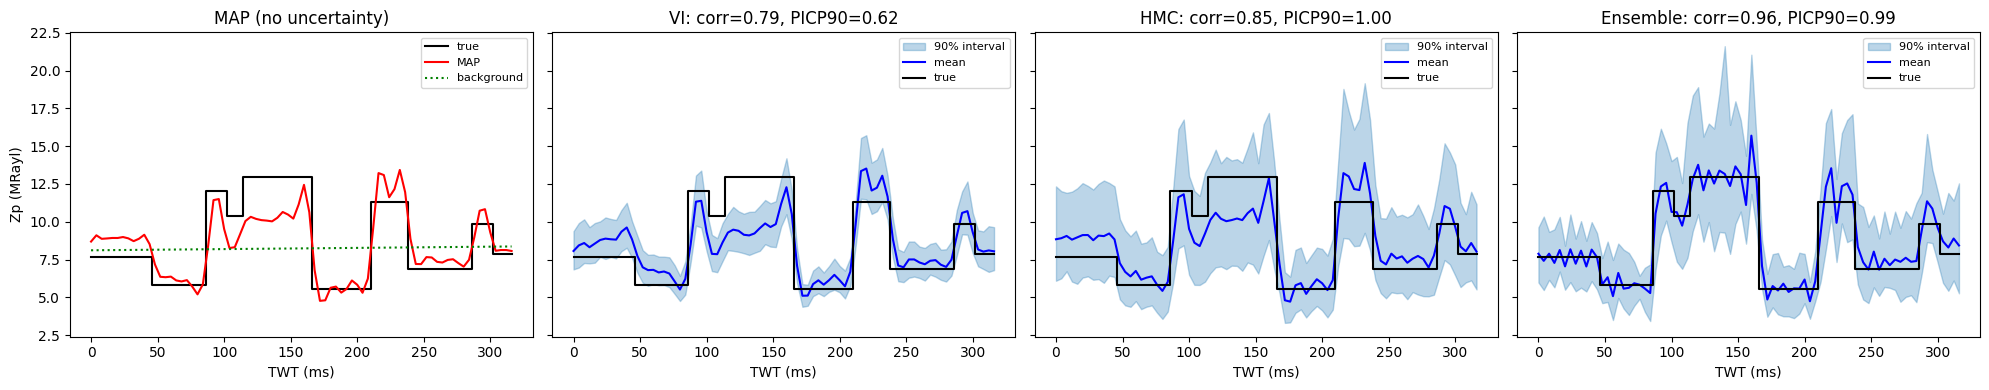

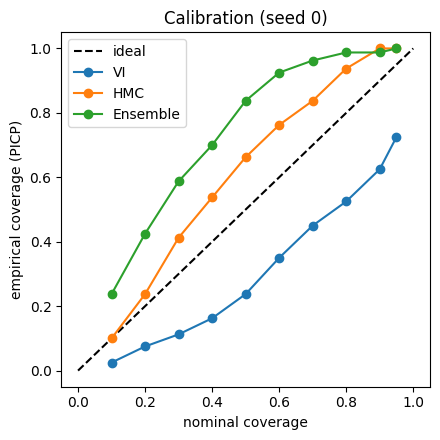

In [ ]:
s0 = SEEDS[0]; R = ALL[s0]; res = R["res"]; z_true, m_lf = R["z_true"], R["m_lf"]
t_ms = np.arange(cfg.n) * cfg.dt * 1000
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t_ms, R["d"], "k"); ax[0].set_title(f"Input: observed seismic trace (seed {s0})"); ax[0].set_xlabel("TWT (ms)")
ax[1].step(t_ms, z_true, "k", where="mid", label="true Zp (hidden from the network)")
ax[1].plot(t_ms, np.exp(m_lf), "g:", label="background (given)")
ax[1].set_title("Answer key and low-frequency background"); ax[1].set_xlabel("TWT (ms)"); ax[1].set_ylabel("Zp (MRayl)")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
ax[0].step(t_ms, z_true, "k", where="mid", label="true"); ax[0].plot(t_ms, R["z_map"], "r", label="MAP")
ax[0].plot(t_ms, np.exp(m_lf), "g:", label="background"); ax[0].set_title("MAP (no uncertainty)")
for a_, k in zip(ax[1:], ["VI", "HMC", "Ensemble"]):
    mn, lo, hi = R["bands"][k]
    a_.fill_between(t_ms, lo, hi, color="tab:blue", alpha=0.3, label="90% interval")
    a_.plot(t_ms, mn, "b", label="mean"); a_.step(t_ms, z_true, "k", where="mid", label="true")
    a_.set_title(f"{k}: corr={res[k]['corr']:.2f}, PICP90={res[k]['picp90']:.2f}")
for a_ in ax: a_.set_xlabel("TWT (ms)"); a_.legend(fontsize=8)
ax[0].set_ylabel("Zp (MRayl)"); plt.tight_layout(); plt.show()

plt.figure(figsize=(4.5, 4.5)); plt.plot([0, 1], [0, 1], "k--", label="ideal")
for k, c in zip(["VI", "HMC", "Ensemble"], ["tab:blue", "tab:orange", "tab:green"]):
    cov = res[k]["coverage"]; plt.plot(list(cov.keys()), list(cov.values()), "o-", color=c, label=k)
plt.xlabel("nominal coverage"); plt.ylabel("empirical coverage (PICP)")
plt.title(f"Calibration (seed {s0})"); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
# Save results (in Colab they appear in the Files panel on the left)
out = dict(per_seed={str(s_): ALL[s_]["res"] for s_ in ALL}, mean_std=summary,
           setup=dict(vars(cfg), seeds=SEEDS, n_params=ALL[SEEDS[0]]["n_params"]))
with open("e1_results_5seeds.json", "w") as f: json.dump(out, f, indent=2)
np.savez("e1_arrays_seed%d.npz" % SEEDS[0], z_true=R["z_true"], d=R["d"], z_map=R["z_map"], z_vi=R["z_vi"], z_hmc=R["z_hmc"], z_ens=R["z_ens"], m_lf=R["m_lf"])
# from google.colab import files; files.download("e1_results_5seeds.json")   # uncomment to download

## How to read the result

* **corr / MAE** compare the *mean* estimate with the hidden true impedance (accuracy).
* **PICP90** is the fraction of true values inside the 90 percent interval. Ideal is about 0.90. Below 0.90 means overconfident, near 1.00 with a very wide interval means too cautious.
* **width90** is the mean width of that interval in MRayl. A narrow interval is only good if PICP90 is also near 0.90.
* **HMC** is the reference for what the posterior should look like. It is not the same as "closest to the truth".
* Run several seeds (change `cfg.seed`) before drawing conclusions. One trace can mislead.